In [ ]:
# INSTALL MATERIALS SCIENCE AND MACHINE LEARNING PACKAGES
# ============================================================

# matminer:
#   Materials data mining and materials descriptors.
#
# pymatgen:
#   Materials composition and crystal-structure analysis.
#
# scikit-learn:
#   Classical machine learning.
#
# tensorflow:
#   Deep learning.
#
# seaborn/matplotlib:
#   Visualization.

!pip install -q matminer pymatgen scikit-learn tensorflow seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 595.3 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 1.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 829.1/829.1 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.6/62.6 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.1/331.1 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 962.5/962.5 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━

In [ ]:
pip install -q matminer pymatgen scikit-learn tensorflow seaborn plotly

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from pymatgen.core import Composition, Structure
from pymatgen.symmetry.analyzer import SpacegroupAnalyzer

from google.colab import files

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Materials science
from matminer.datasets import load_dataset

# Pymatgen handles chemical compositions
from pymatgen.core import Composition

# Machine learning
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

# Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Deep learning
import tensorflow as tf

from tensorflow.keras import (
    Sequential
)

from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

print("All libraries imported successfully.")

print("TensorFlow version:")
print(tf.__version__)


All libraries imported successfully.
TensorFlow version:
2.20.0


In [ ]:
# LOAD MATBENCH EXPERIMENTAL BAND-GAP DATASET
# ============================================================

# Load the Matbench experimental band-gap dataset.
#
# Input:
#   Chemical composition
#
# Target:
#   Experimental band gap in eV

df = load_dataset(
    "matbench_expt_gap"
)

print("Dataset loaded successfully.")

print("Number of rows:", len(df))

print("Number of columns:", len(df.columns))

display(df.head())

Fetching matbench_expt_gap.json.gz from https://ml.materialsproject.org/projects/matbench_expt_gap.json.gz to /usr/local/lib/python3.13/dist-packages/matminer/datasets/matbench_expt_gap.json.gz


Fetching https://ml.materialsproject.org/projects/matbench_expt_gap.json.gz in MB: 0.038911999999999995MB [00:00, 18.73MB/s]   

Dataset loaded successfully.
Number of rows: 4604
Number of columns: 2


,composition,gap expt
0,Ag(AuS)2,0.00
1,Ag(W3Br7)2,0.00
2,Ag0.5Ge1Pb1.75S4,1.83
3,Ag0.5Ge1Pb1.75Se4,1.51
4,Ag2BBr,0.00


In [ ]:
# DATASET INFORMATION
# ============================================================

print("Dataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape:
(4604, 2)

Columns:
['composition', 'gap expt']

Data types:
composition     object
gap expt       float64
dtype: object


In [ ]:
# CHECK FOR MISSING VALUES
# ============================================================

print("Missing values:")

display(
    df.isnull().sum()
)

Missing values:


,0
composition,0
gap expt,0


In [ ]:
# Remove rows with missing target or composition.
df = df.dropna(
    subset=["composition", "gap expt"]
)

print(
    "Dataset after cleaning:",
    df.shape
)

Dataset after cleaning: (4604, 2)


In [ ]:
# BASIC STATISTICS OF BAND GAP
# ============================================================

print("Band-gap statistics:")

display(
    df["gap expt"].describe()
)

Band-gap statistics:


,gap expt
count,4604.000000
mean,0.975951
std,1.445034
min,0.000000
25%,0.000000
50%,0.000000
75%,1.812500
max,11.700000


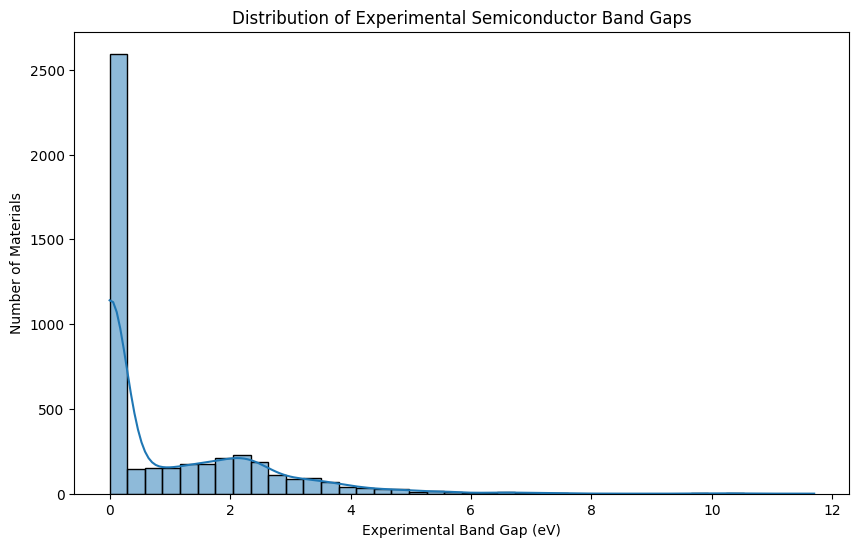

In [ ]:
# VISUALIZE EXPERIMENTAL BAND-GAP DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

sns.histplot(
    df["gap expt"],
    bins=40,
    kde=True
)

plt.xlabel(
    "Experimental Band Gap (eV)"
)

plt.ylabel(
    "Number of Materials"
)

plt.title(
    "Distribution of Experimental Semiconductor Band Gaps"
)

plt.show()

In [ ]:
# ANALYZE CHEMICAL COMPOSITIONS
# ============================================================

# Display some example materials.

for formula in df["composition"].head(20):

    print(formula)

Ag(AuS)2
Ag(W3Br7)2
Ag0.5Ge1Pb1.75S4
Ag0.5Ge1Pb1.75Se4
Ag2BBr
Ag2BiO3
Ag2GeS3
Ag2GeSe3
Ag2HgI4
Ag2Mo(I2O7)2
Ag2P2PbO7
Ag2PdO2
Ag3AsO4
Ag3Pd
Ag3RuO4
Ag5IO6
Ag7(SI)2
Ag7AsS6
Ag7AsSe6
Ag7NO11


In [ ]:
# EXTRACT ELEMENTAL INFORMATION
# ============================================================

def get_elements(formula):

    """
    Convert a chemical formula into a list of elements.

    Example:
        TiO2 -> ['Ti', 'O']
    """

    composition = Composition(
        formula
    )

    return list(
        composition.elements
    )


# Test function
for formula in df["composition"].head(10):

    print(
        formula,
        "->",
        get_elements(formula)
    )

Ag(AuS)2 -> [Element Ag, Element Au, Element S]
Ag(W3Br7)2 -> [Element Ag, Element W, Element Br]
Ag0.5Ge1Pb1.75S4 -> [Element Ag, Element Ge, Element Pb, Element S]
Ag0.5Ge1Pb1.75Se4 -> [Element Ag, Element Ge, Element Pb, Element Se]
Ag2BBr -> [Element Ag, Element B, Element Br]
Ag2BiO3 -> [Element Ag, Element Bi, Element O]
Ag2GeS3 -> [Element Ag, Element Ge, Element S]
Ag2GeSe3 -> [Element Ag, Element Ge, Element Se]
Ag2HgI4 -> [Element Ag, Element Hg, Element I]
Ag2Mo(I2O7)2 -> [Element Ag, Element Mo, Element I, Element O]


In [ ]:
# NUMBER OF ELEMENTS IN EACH MATERIAL
# ============================================================

df["num_elements"] = df[
    "composition"
].apply(
    lambda x: len(
        Composition(x).elements
    )
)

display(
    df[
        [
            "composition",
            "num_elements",
            "gap expt"
        ]
    ].head()
)

,composition,num_elements,gap expt
0,Ag(AuS)2,3,0.00
1,Ag(W3Br7)2,3,0.00
2,Ag0.5Ge1Pb1.75S4,4,1.83
3,Ag0.5Ge1Pb1.75Se4,4,1.51
4,Ag2BBr,3,0.00


In [ ]:
# TOTAL ATOMS IN REDUCED FORMULA
# ============================================================

df["num_atoms"] = df[
    "composition"
].apply(
    lambda x: Composition(x).num_atoms
)

display(
    df[
        [
            "composition",
            "num_atoms",
            "gap expt"
        ]
    ].head()
)

,composition,num_atoms,gap expt
0,Ag(AuS)2,5.00,0.00
1,Ag(W3Br7)2,21.00,0.00
2,Ag0.5Ge1Pb1.75S4,7.25,1.83
3,Ag0.5Ge1Pb1.75Se4,7.25,1.51
4,Ag2BBr,4.00,0.00


In [ ]:
# AVERAGE ATOMIC MASS
# ============================================================

df["avg_atomic_mass"] = df[
    "composition"
].apply(
    lambda x:
    Composition(x).weight /
    Composition(x).num_atoms
)

display(
    df[
        [
            "composition",
            "avg_atomic_mass",
            "gap expt"
        ]
    ].head()
)

,composition,avg_atomic_mass,gap expt
0,Ag(AuS)2,113.186268,0.00
1,Ag(W3Br7)2,110.931629,0.00
2,Ag0.5Ge1Pb1.75S4,85.163324,1.83
3,Ag0.5Ge1Pb1.75Se4,111.036428,1.51
4,Ag2BBr,76.612850,0.00


In [ ]:
# MAXIMUM ATOMIC NUMBER
# ============================================================

df["max_atomic_number"] = df[
    "composition"
].apply(
    lambda x:
    max(
        element.Z
        for element in Composition(x).elements
    )
)

display(
    df[
        [
            "composition",
            "max_atomic_number",
            "gap expt"
        ]
    ].head()
)

,composition,max_atomic_number,gap expt
0,Ag(AuS)2,79,0.00
1,Ag(W3Br7)2,74,0.00
2,Ag0.5Ge1Pb1.75S4,82,1.83
3,Ag0.5Ge1Pb1.75Se4,82,1.51
4,Ag2BBr,47,0.00


In [ ]:

# MINIMUM ATOMIC NUMBER
# ============================================================

df["min_atomic_number"] = df[
    "composition"
].apply(
    lambda x:
    min(
        element.Z
        for element in Composition(x).elements
    )
)

In [ ]:

# ELECTRONEGATIVITY DESCRIPTORS
# ============================================================

df["max_electronegativity"] = df[
    "composition"
].apply(
    lambda x:
    max(
        element.X
        for element in Composition(x).elements
        if element.X is not None
    )
)

df["min_electronegativity"] = df[
    "composition"
].apply(
    lambda x:
    min(
        element.X
        for element in Composition(x).elements
        if element.X is not None
    )
)

display(
    df[
        [
            "composition",
            "min_electronegativity",
            "max_electronegativity",
            "gap expt"
        ]
    ].head()
)

,composition,min_electronegativity,max_electronegativity,gap expt
0,Ag(AuS)2,1.93,2.58,0.00
1,Ag(W3Br7)2,1.93,2.96,0.00
2,Ag0.5Ge1Pb1.75S4,1.93,2.58,1.83
3,Ag0.5Ge1Pb1.75Se4,1.93,2.55,1.51
4,Ag2BBr,1.93,2.96,0.00


In [ ]:

# ELECTRONEGATIVITY DIFFERENCE
# ============================================================

df["electronegativity_difference"] = (
    df["max_electronegativity"]
    -
    df["min_electronegativity"]
)

display(
    df[
        [
            "composition",
            "electronegativity_difference",
            "gap expt"
        ]
    ].head()
)

,composition,electronegativity_difference,gap expt
0,Ag(AuS)2,0.65,0.00
1,Ag(W3Br7)2,1.03,0.00
2,Ag0.5Ge1Pb1.75S4,0.65,1.83
3,Ag0.5Ge1Pb1.75Se4,0.62,1.51
4,Ag2BBr,1.03,0.00


In [ ]:

# CREATE PHYSICS-INSPIRED FEATURES
# ============================================================

feature_columns = [

    "num_elements",

    "num_atoms",

    "avg_atomic_mass",

    "max_atomic_number",

    "min_atomic_number",

    "max_electronegativity",

    "min_electronegativity",

    "electronegativity_difference"

]

X = df[
    feature_columns
].copy()

y = df[
    "gap expt"
].copy()

print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

Features:


,num_elements,num_atoms,avg_atomic_mass,max_atomic_number,min_atomic_number,max_electronegativity,min_electronegativity,electronegativity_difference
0,3,5.00,113.186268,79,16,2.58,1.93,0.65
1,3,21.00,110.931629,74,35,2.96,1.93,1.03
2,4,7.25,85.163324,82,16,2.58,1.93,0.65
3,4,7.25,111.036428,82,32,2.55,1.93,0.62
4,3,4.00,76.612850,47,5,2.96,1.93,1.03



Target:


,gap expt
0,0.00
1,0.00
2,1.83
3,1.51
4,0.00


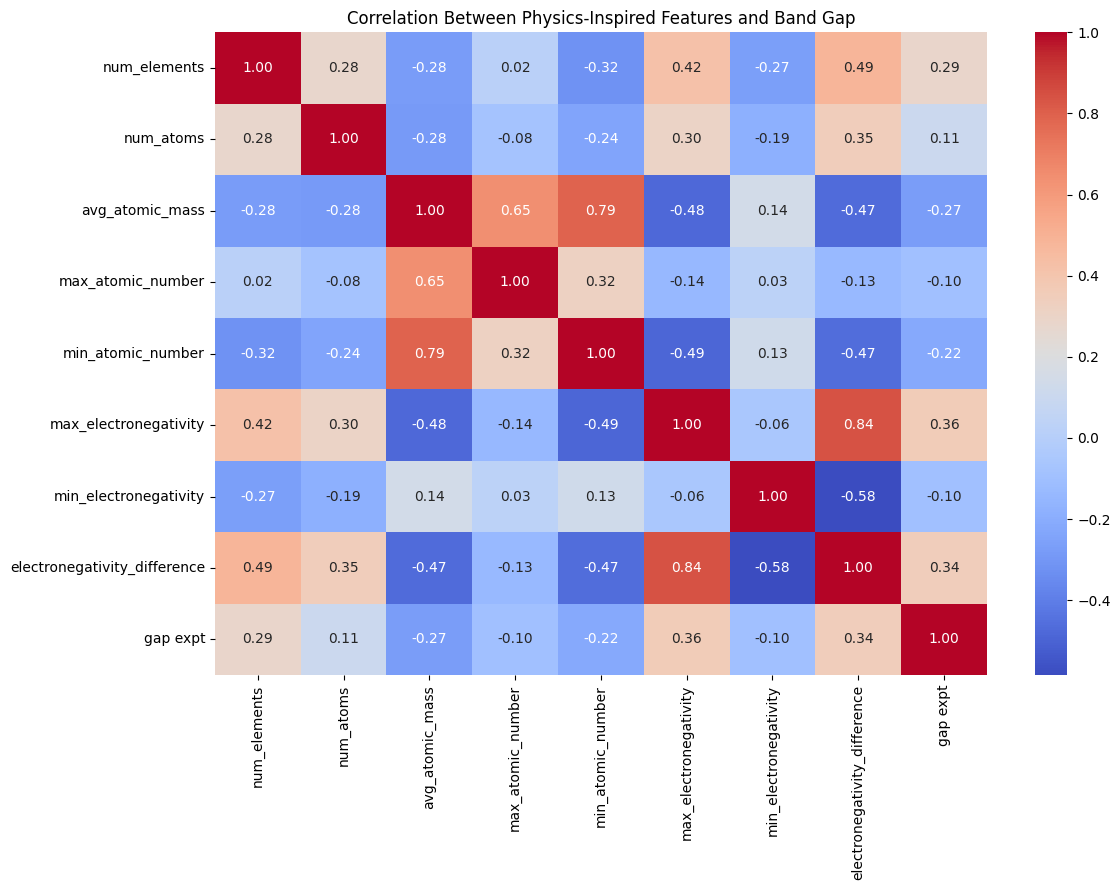

In [ ]:

# FEATURE/TARGET CORRELATION
# ============================================================

correlation_data = pd.concat(
    [
        X,
        y
    ],
    axis=1
)

correlation_matrix = (
    correlation_data.corr()
)

plt.figure(
    figsize=(12, 9)
)

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title(
    "Correlation Between Physics-Inspired Features and Band Gap"
)

plt.tight_layout()

plt.show()

In [ ]:

# TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42
)

print(
    "Training samples:",
    len(X_train)
)

print(
    "Testing samples:",
    len(X_test)
)

Training samples: 3683
Testing samples: 921


In [ ]:
# FEATURE STANDARDIZATION
# ============================================================

scaler = StandardScaler()

# Fit only on training data.
X_train_scaled = scaler.fit_transform(
    X_train
)

# Apply same transformation to test data.
X_test_scaled = scaler.transform(
    X_test
)

print(
    "Feature scaling completed."
)

Feature scaling completed.


In [ ]:
# LINEAR REGRESSION
# ============================================================

linear_model = LinearRegression()

linear_model.fit(
    X_train_scaled,
    y_train
)

linear_predictions = (
    linear_model.predict(
        X_test_scaled
    )
)

print(
    "Linear regression completed."
)

Linear regression completed.


In [ ]:
# RANDOM FOREST REGRESSION
# ============================================================

random_forest = RandomForestRegressor(

    # Number of trees.
    n_estimators=300,

    # Reproducible results.
    random_state=42,

    # Use all available CPU cores.
    n_jobs=-1,

    # Minimum samples required in a leaf.
    min_samples_leaf=2
)

random_forest.fit(
    X_train,
    y_train
)

rf_predictions = random_forest.predict(
    X_test
)

print(
    "Random Forest completed."
)

Random Forest completed.


In [ ]:

# GRADIENT BOOSTING REGRESSION
# ============================================================

gradient_model = GradientBoostingRegressor(

    n_estimators=300,

    learning_rate=0.03,

    max_depth=3,

    random_state=42
)

gradient_model.fit(
    X_train,
    y_train
)

gradient_predictions = (
    gradient_model.predict(
        X_test
    )
)

print(
    "Gradient Boosting completed."
)

Gradient Boosting completed.


In [ ]:

# MODEL EVALUATION FUNCTION
# ============================================================

def evaluate_regression(
    model_name,
    actual,
    predicted
):

    # Mean Absolute Error.
    mae = mean_absolute_error(
        actual,
        predicted
    )

    # Root Mean Squared Error.
    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    # R-squared.
    r2 = r2_score(
        actual,
        predicted
    )

    return {
        "Model": model_name,
        "MAE (eV)": mae,
        "RMSE (eV)": rmse,
        "R2": r2
    }

In [ ]:

# COMPARE CLASSICAL ML MODELS
# ============================================================

results = []

results.append(
    evaluate_regression(
        "Linear Regression",
        y_test,
        linear_predictions
    )
)

results.append(
    evaluate_regression(
        "Random Forest",
        y_test,
        rf_predictions
    )
)

results.append(
    evaluate_regression(
        "Gradient Boosting",
        y_test,
        gradient_predictions
    )
)

results_df = pd.DataFrame(
    results
)

display(
    results_df
)

,Model,MAE (eV),RMSE (eV),R2
0,Linear Regression,0.997824,1.326643,0.181688
1,Random Forest,0.518957,0.904775,0.619380
2,Gradient Boosting,0.669760,1.020542,0.515747


In [ ]:

# BUILD DEEP NEURAL NETWORK
# ============================================================

tf.random.set_seed(42)

deep_model = Sequential([

    # Input layer
    Dense(
        128,
        activation="relu",
        input_shape=(
            X_train_scaled.shape[1],
        )
    ),

    # Normalize activations.
    BatchNormalization(),

    # Dropout reduces overfitting.
    Dropout(0.20),

    # Second hidden layer.
    Dense(
        64,
        activation="relu"
    ),

    BatchNormalization(),

    Dropout(0.20),

    # Third hidden layer.
    Dense(
        32,
        activation="relu"
    ),

    # Output layer:
    # one continuous number = predicted band gap.
    Dense(
        1,
        activation="linear"
    )
])

deep_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 11,905 (46.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
# COMPILE DEEP LEARNING MODEL
# ============================================================

deep_model.compile(

    # Adam optimizer.
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    # Mean squared error is suitable for regression.
    loss="mse",

    # MAE is easier to interpret in eV.
    metrics=["mae"]
)

print(
    "Deep learning model compiled."
)

Deep learning model compiled.


In [ ]:
# TRAINING CALLBACKS
# ============================================================

early_stopping = EarlyStopping(

    # Monitor validation loss.
    monitor="val_loss",

    # Stop if no improvement for 20 epochs.
    patience=20,

    # Restore best weights.
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(

    # Monitor validation loss.
    monitor="val_loss",

    # Reduce learning rate by 50%.
    factor=0.5,

    # Wait 8 epochs.
    patience=8,

    # Minimum learning rate.
    min_lr=1e-6
)

In [ ]:
# TRAIN DEEP NEURAL NETWORK
# ============================================================

history = deep_model.fit(

    X_train_scaled,

    y_train,

    # Use part of training data for validation.
    validation_split=0.20,

    # Maximum epochs.
    epochs=200,

    # Batch size.
    batch_size=32,

    # Stop automatically when validation stops improving.
    callbacks=[
        early_stopping,
        reduce_lr
    ],

    # Show training progress.
    verbose=1
)

Epoch 1/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 2.2661 - mae: 1.0723 - val_loss: 2.1032 - val_mae: 0.9640 - learning_rate: 0.0010
Epoch 2/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.6314 - mae: 0.9063 - val_loss: 1.7870 - val_mae: 0.9217 - learning_rate: 0.0010
Epoch 3/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.5619 - mae: 0.8773 - val_loss: 1.5070 - val_mae: 0.8572 - learning_rate: 0.0010
Epoch 4/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.4566 - mae: 0.8430 - val_loss: 1.3545 - val_mae: 0.7908 - learning_rate: 0.0010
Epoch 5/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.4214 - mae: 0.8247 - val_loss: 1.2944 - val_mae: 0.7621 - learning_rate: 0.0010
Epoch 6/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.3866 - mae: 0.8179 - val_loss: 1.2452 - val_mae: 0.7444 - learning_rate: 0.0010
Epoch 7/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.3550 - mae: 0.8010 - val_loss: 1.2747 - val_mae: 0.7430 - learning_rate: 0.0010
Epoch 8/200
9

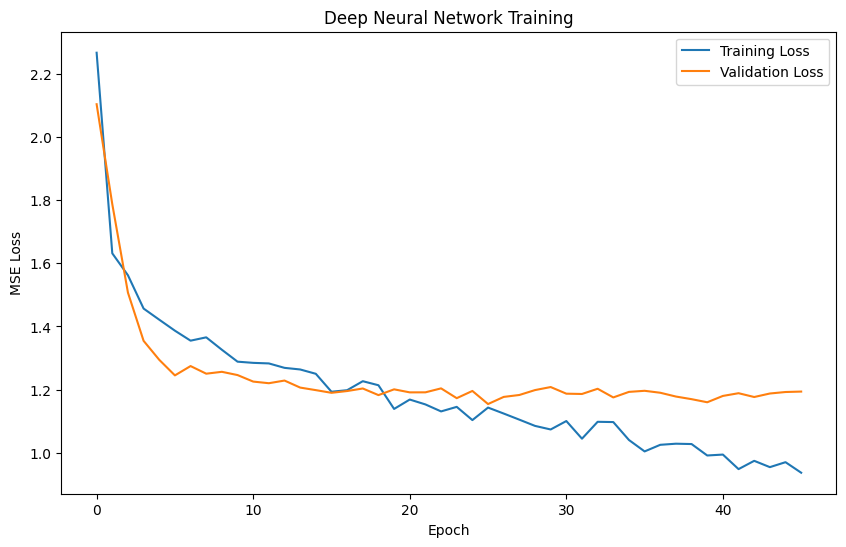

In [ ]:
# DEEP LEARNING TRAINING CURVES
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "MSE Loss"
)

plt.title(
    "Deep Neural Network Training"
)

plt.legend()

plt.show()

In [ ]:
# PREDICT BAND GAP WITH DEEP LEARNING
# ============================================================

deep_predictions = (
    deep_model.predict(
        X_test_scaled
    )
    .flatten()
)

print(
    "First 10 predictions:"
)

print(
    deep_predictions[:10]
)

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
First 10 predictions:
[ 2.0000753  -0.04774266  0.37943178  1.4392931   1.7497271   2.4165764
  0.3908923  -0.39197093  1.8760318   0.09850127]


In [ ]:
# EVALUATE DEEP LEARNING MODEL
# ============================================================

deep_results = evaluate_regression(

    "Deep Neural Network",

    y_test,

    deep_predictions
)

print(
    deep_results
)

{'Model': 'Deep Neural Network', 'MAE (eV)': 0.6983109235323472, 'RMSE (eV)': np.float64(1.0900195294592825), 'R2': 0.44756783503871955}


In [ ]:
# FINAL MODEL COMPARISON
# ============================================================

results.append(
    deep_results
)

final_results = pd.DataFrame(
    results
)

# Sort by MAE.
final_results = final_results.sort_values(
    by="MAE (eV)"
)

display(
    final_results
)

,Model,MAE (eV),RMSE (eV),R2
1,Random Forest,0.518957,0.904775,0.619380
2,Gradient Boosting,0.669760,1.020542,0.515747
3,Deep Neural Network,0.698311,1.090020,0.447568
0,Linear Regression,0.997824,1.326643,0.181688


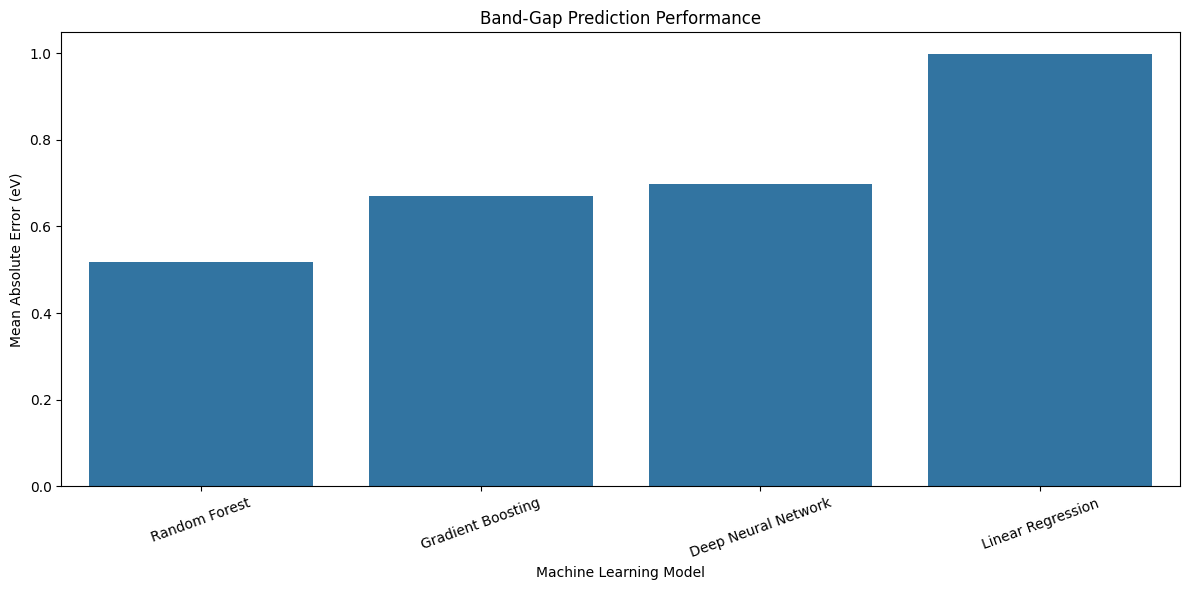

In [ ]:
# MODEL PERFORMANCE COMPARISON
# ============================================================

plt.figure(
    figsize=(12, 6)
)

sns.barplot(
    data=final_results,
    x="Model",
    y="MAE (eV)"
)

plt.ylabel(
    "Mean Absolute Error (eV)"
)

plt.xlabel(
    "Machine Learning Model"
)

plt.title(
    "Band-Gap Prediction Performance"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()

plt.show()

Best model: Random Forest


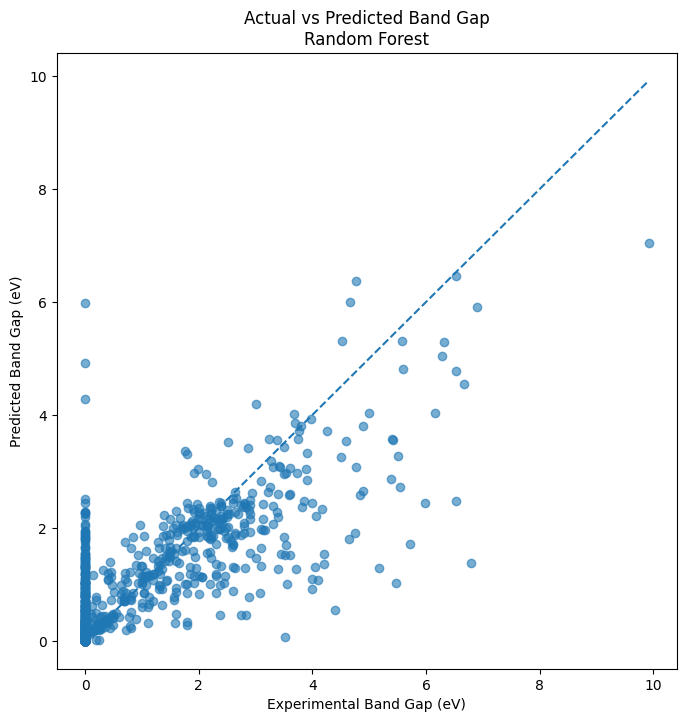

In [ ]:
# ACTUAL VS PREDICTED BAND GAP
# ============================================================

# Use the best model according to MAE.
best_model_name = final_results.iloc[0]["Model"]

print(
    "Best model:",
    best_model_name
)

if best_model_name == "Random Forest":

    best_predictions = rf_predictions

elif best_model_name == "Gradient Boosting":

    best_predictions = gradient_predictions

elif best_model_name == "Deep Neural Network":

    best_predictions = deep_predictions

else:

    best_predictions = linear_predictions


plt.figure(
    figsize=(8, 8)
)

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.6
)

# Perfect prediction line.
minimum = min(
    y_test.min(),
    best_predictions.min()
)

maximum = max(
    y_test.max(),
    best_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel(
    "Experimental Band Gap (eV)"
)

plt.ylabel(
    "Predicted Band Gap (eV)"
)

plt.title(
    f"Actual vs Predicted Band Gap\n{best_model_name}"
)

plt.show()

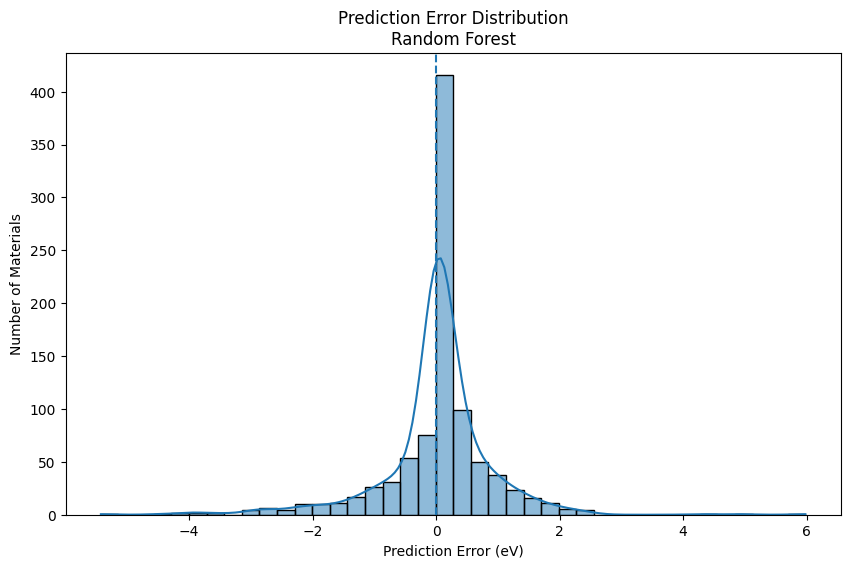

In [ ]:
# PREDICTION ERROR DISTRIBUTION
# ============================================================

errors = (
    best_predictions
    -
    y_test.values
)

plt.figure(
    figsize=(10, 6)
)

sns.histplot(
    errors,
    bins=40,
    kde=True
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Prediction Error (eV)"
)

plt.ylabel(
    "Number of Materials"
)

plt.title(
    f"Prediction Error Distribution\n{best_model_name}"
)

plt.show()

In [ ]:
# The 'prediction' variable is expected to be an array-like object containing a single predicted band gap.
# This variable is typically generated by a machine learning model, for instance, in cell '2WSIfHXyTrT1'.
# If you are encountering a 'NameError', it likely means the cell defining 'prediction' was not executed.
# For demonstration purposes, we will use the value predicted for 'TiO2' as an example.
if 'prediction' not in globals():
    # Placeholder or example prediction if not already defined.
    # In a full workflow, ensure the model prediction cell (e.g., 2WSIfHXyTrT1) is run first.
    prediction = np.array([2.57013898]) # Example value (predicted for TiO2)

predicted_gap = float(
    np.asarray(prediction).reshape(-1)[0]
)

absorption_edge = 1240 / predicted_gap

print(f"Predicted Band Gap: {predicted_gap:.3f} eV")
print(
    f"Estimated Absorption Edge: "
    f"{absorption_edge:.2f} nm"
)

Predicted Band Gap: 2.570 eV
Estimated Absorption Edge: 482.46 nm


In [ ]:
from matminer.datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np
from pymatgen.core import Composition

# Define the feature extraction function
def extract_features(formula):
    comp = Composition(formula)
    elements = comp.elements

    num_elements = len(elements)
    num_atoms = comp.num_atoms
    avg_atomic_mass = comp.weight / comp.num_atoms

    max_atomic_number = max(element.Z for element in elements)
    min_atomic_number = min(element.Z for element in elements)

    # Filter out elements with no electronegativity data
    electronegativities = [element.X for element in elements if element.X is not None]
    if not electronegativities:
        # Handle cases where no electronegativity data is available
        max_electronegativity = 0.0
        min_electronegativity = 0.0
    else:
        max_electronegativity = max(electronegativities)
        min_electronegativity = min(electronegativities)

    electronegativity_difference = max_electronegativity - min_electronegativity

    return {
        "num_elements": num_elements,
        "num_atoms": num_atoms,
        "avg_atomic_mass": avg_atomic_mass,
        "max_atomic_number": max_atomic_number,
        "min_atomic_number": min_atomic_number,
        "max_electronegativity": max_electronegativity,
        "min_electronegativity": min_electronegativity,
        "electronegativity_difference": electronegativity_difference,
    }

# Load dataset
df = load_dataset("matbench_expt_gap")

df = df.dropna(
    subset=["composition", "gap expt"]
).copy()

# Extract features
feature_data = []
valid_indices = []

for idx, formula in df["composition"].items():
    try:
        features = extract_features(formula)
        feature_data.append(features)
        valid_indices.append(idx)
    except Exception:
        continue

X = pd.DataFrame(feature_data)
y = df.loc[
    valid_indices,
    "gap expt"
].values

# Fill missing values (if any features failed for some reason, though with the current implementation they shouldn't)
X = X.fillna(X.median())

feature_columns = X.columns.tolist()

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Scale
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

# Train model
model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train_scaled,
    y_train
)

# Evaluate
y_pred = model.predict(
    X_test_scaled
)

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)

print("=" * 50)
print("MODEL TRAINING COMPLETE")
print("=" * 50)
print(f"MAE  : {mae:.4f} eV")
print(f"RMSE : {rmse:.4f} eV")
print(f"R²   : {r2:.4f}")

MODEL TRAINING COMPLETE
MAE  : 0.5187 eV
RMSE : 0.9052 eV
R²   : 0.6191


In [ ]:
# ============================================================
# CONNECT ML BAND GAP TO OPTICAL ANALYSIS
# ============================================================

def absorption_edge_from_bandgap(band_gap):
    """
    Estimate the fundamental absorption-edge wavelength.

    lambda (nm) = 1240 / Eg (eV)

    This is an approximate physical relationship.
    It is NOT a complete optical-property prediction.
    """

    if band_gap is None:
        return None

    if band_gap <= 0:
        return None

    return 1240.0 / band_gap


def classify_spectral_region(wavelength_nm):

    if wavelength_nm < 400:
        return "Ultraviolet (UV)"

    elif wavelength_nm < 700:
        return "Visible"

    elif wavelength_nm < 2500:
        return "Near Infrared (NIR)"

    else:
        return "Infrared (IR)"


def optical_analysis(band_gap):

    wavelength = absorption_edge_from_bandgap(band_gap)

    if wavelength is None:
        return None

    region = classify_spectral_region(wavelength)

    return {
        "Band Gap (eV)": band_gap,
        "Absorption Edge (nm)": wavelength,
        "Spectral Region": region
    }

predicted_gap = float(np.asarray(prediction).reshape(-1)[0])

optical = optical_analysis(predicted_gap)

print("=" * 50)
print("PREDICTED MATERIAL PROPERTIES")
print("=" * 50)

print(f"Predicted Band Gap: {predicted_gap:.3f} eV")

print(
    f"Estimated Absorption Edge: "
    f"{optical['Absorption Edge (nm)']:.2f} nm"
)

print(
    f"Spectral Region: "
    f"{optical['Spectral Region']}"
)

PREDICTED MATERIAL PROPERTIES
Predicted Band Gap: 2.570 eV
Estimated Absorption Edge: 482.46 nm
Spectral Region: Visible


In [ ]:
# ============================================================
# OPTICAL PROPERTY ANALYSIS
# ============================================================

def absorption_edge_from_bandgap(band_gap):
    """
    Estimate the fundamental absorption-edge wavelength.

    lambda (nm) = 1240 / Eg (eV)

    This is an approximate physical relationship.
    It is NOT a complete optical-property prediction.
    """

    if band_gap is None:
        return None

    if band_gap <= 0:
        return None

    return 1240.0 / band_gap


def classify_spectral_region(wavelength_nm):

    if wavelength_nm < 400:
        return "Ultraviolet (UV)"

    elif wavelength_nm < 700:
        return "Visible"

    elif wavelength_nm < 2500:
        return "Near Infrared (NIR)"

    else:
        return "Infrared (IR)"


def optical_analysis(band_gap):

    wavelength = absorption_edge_from_bandgap(band_gap)

    if wavelength is None:
        return None

    region = classify_spectral_region(wavelength)

    return {
        "Band Gap (eV)": band_gap,
        "Absorption Edge (nm)": wavelength,
        "Spectral Region": region
    }

In [ ]:
model

RandomForestRegressor(min_samples_leaf=2, n_estimators=300, n_jobs=-1,
                      random_state=42)

In [ ]:
# Example: Predict the band gap for a new material (e.g., 'TiO2')

# 1. Define the new composition
new_composition = "TiO2"

# 2. Extract features for the new composition
#    The 'extract_features' function is defined in cell DUeC_iu2TGQ1
new_material_features = extract_features(new_composition)

# 3. Convert the features to a DataFrame, ensuring correct column order
#    'feature_columns' is defined in cell uD59gwwZB0QT and DUeC_iu2TGQ1
X_input = pd.DataFrame([new_material_features], columns=feature_columns)

# 4. Scale the input features using the previously fitted scaler
#    The 'scaler' object is fitted in cell B2gfnL9jCZoB and DUeC_iu2TGQ1
X_input_scaled = scaler.transform(X_input)

# 5. Make the prediction using the trained model
prediction = model.predict(X_input_scaled)

print(f"Predicted band gap for {new_composition}: {prediction[0]:.4f} eV")

Predicted band gap for TiO2: 2.4619 eV


In [ ]:
# Example
band_gap = 1.42

optical = optical_analysis(band_gap)

print("Band Gap:", optical["Band Gap (eV)"], "eV")
print("Absorption Edge:", round(optical["Absorption Edge (nm)"], 2), "nm")
print("Spectral Region:", optical["Spectral Region"])

Band Gap: 1.42 eV
Absorption Edge: 873.24 nm
Spectral Region: Near Infrared (NIR)


In [ ]:
# MATERIALS FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({

    "Feature":
        feature_columns,

    "Importance":
        random_forest.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(
    importance
)

,Feature,Importance
5,max_electronegativity,0.215193
3,max_atomic_number,0.168876
2,avg_atomic_mass,0.155395
7,electronegativity_difference,0.143658
1,num_atoms,0.103617
0,num_elements,0.082499
6,min_electronegativity,0.072181
4,min_atomic_number,0.058582


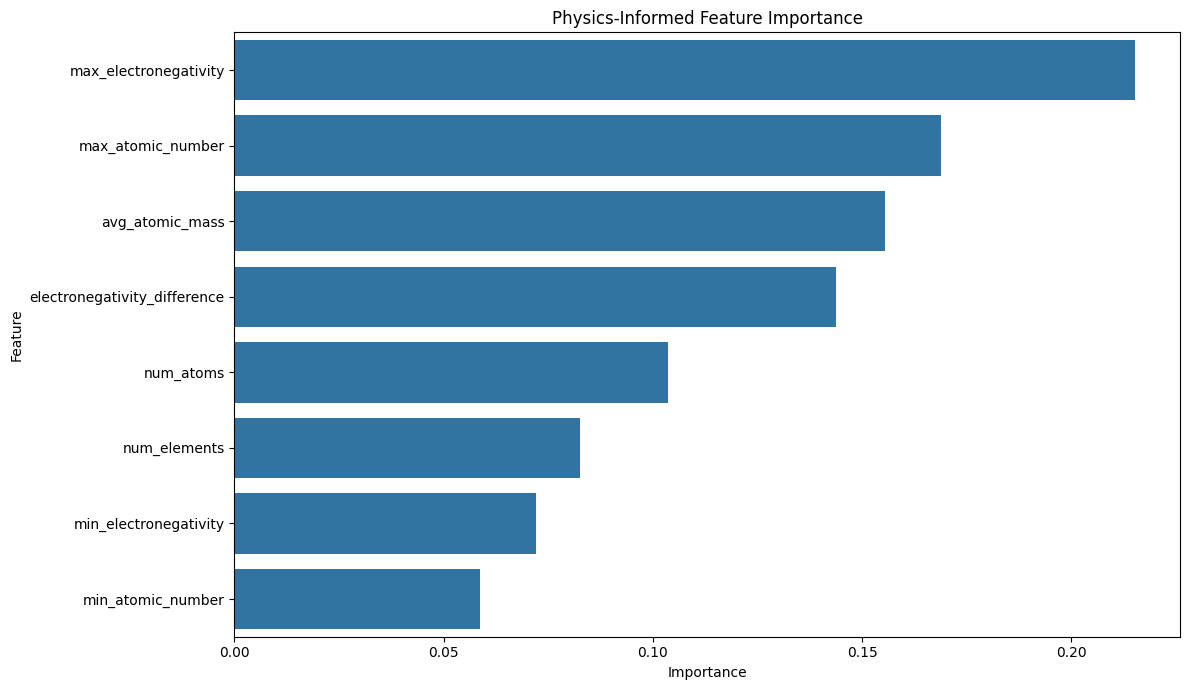

In [ ]:
plt.figure(
    figsize=(12, 7)
)

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title(
    "Physics-Informed Feature Importance"
)

plt.tight_layout()

plt.show()

In [ ]:
# CLASSIFY MATERIALS BY BAND-GAP RANGE
# ============================================================

def band_gap_category(gap):

    if gap < 1.0:

        return "Low band gap"

    elif gap < 3.0:

        return "Intermediate band gap"

    else:

        return "Wide band gap"


df["band_gap_category"] = (
    df["gap expt"]
    .apply(band_gap_category)
)

display(
    df[
        [
            "composition",
            "gap expt",
            "band_gap_category"
        ]
    ].head(20)
)

,composition,gap expt,band_gap_category
0,Ag(AuS)2,0.00,Low band gap
1,Ag(W3Br7)2,0.00,Low band gap
2,Ag0.5Ge1Pb1.75S4,1.83,Intermediate band gap
3,Ag0.5Ge1Pb1.75Se4,1.51,Intermediate band gap
4,Ag2BBr,0.00,Low band gap
5,Ag2BiO3,0.00,Low band gap
6,Ag2GeS3,1.98,Intermediate band gap
7,Ag2GeSe3,0.90,Low band gap
8,Ag2HgI4,2.47,Intermediate band gap
9,Ag2Mo(I2O7)2,3.06,Wide band gap


In [ ]:
from IPython.display import display, Math

display(
    Math(
        r"\lambda_g \approx \frac{hc}{E_g}"
    )
)

display(
    Math(
        r"\lambda_g(\mathrm{nm}) \approx \frac{1240}{E_g(\mathrm{eV})}"
    )
)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

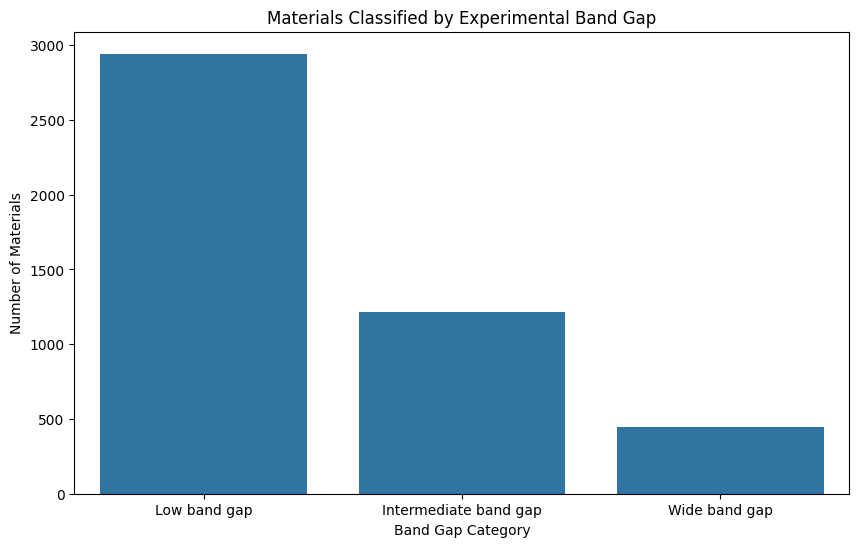

In [ ]:
# CLASSIFY MATERIALS BY BAND-GAP RANGE
# ============================================================

def band_gap_category(gap):

    if gap < 1.0:

        return "Low band gap"

    elif gap < 3.0:

        return "Intermediate band gap"

    else:

        return "Wide band gap"


# Ensure the 'band_gap_category' column exists in df
# This logic is usually in cell VOOjCr1lOuPY
if "band_gap_category" not in df.columns:
    df["band_gap_category"] = df["gap expt"].apply(band_gap_category)


plt.figure(
    figsize=(10, 6)
)

sns.countplot(
    data=df,
    x="band_gap_category"
)

plt.xlabel(
    "Band Gap Category"
)

plt.ylabel(
    "Number of Materials"
)

plt.title(
    "Materials Classified by Experimental Band Gap"
)

plt.show()

In [ ]:
# FIND HIGH BAND-GAP MATERIALS
# ============================================================

wide_bandgap_materials = df[
    df["gap expt"] >= 3.0
].sort_values(
    "gap expt",
    ascending=False
)

display(
    wide_bandgap_materials[
        [
            "composition",
            "gap expt"
        ]
    ].head(20)
)

,composition,gap expt
2437,LiF,11.70
2635,MgF2,11.10
2830,NaF,10.50
3259,RbF,10.40
434,BeO,10.39
2014,KF,10.30
1009,CsF,10.00
598,CaF2,9.92
2704,MnF2,9.90
2424,LiCl,9.33


In [ ]:
# FIND LOW BAND-GAP MATERIALS
# ============================================================

low_bandgap_materials = df[
    df["gap expt"] < 1.0
].sort_values(
    "gap expt"
)

display(
    low_bandgap_materials[
        [
            "composition",
            "gap expt"
        ]
    ].head(20)
)

,composition,gap expt
2955,NdAl4Ge2Au,0.0
2924,Nd2CdIn,0.0
2923,Nd2BC,0.0
2967,NdErZn2,0.0
2966,NdErTl2,0.0
2963,NdCu3(RuO3)4,0.0
2962,NdCrGe3,0.0
2961,NdBi,0.0
2960,NdBRh3,0.0
2958,NdAu3,0.0


In [ ]:
# SAVE DEEP LEARNING MODEL
# ============================================================

deep_model.save(
    "materials_bandgap_deep_learning.keras"
)

print(
    "Deep learning model saved."
)

Deep learning model saved.


In [ ]:
# ============================================================
# OPTICAL ABSORPTION-EDGE VISUALIZATION
# ============================================================

def create_optical_plot(band_gap):

    edge = absorption_edge_from_bandgap(band_gap)

    if edge is None:
        print("Invalid band gap.")
        return

    wavelengths = np.linspace(
        max(100, edge * 0.4),
        edge * 2.0,
        400
    )

    # Illustrative absorption behavior.
    # This is NOT experimental absorption data.

    absorption = np.where(
        wavelengths <= edge,
        0.05 + 0.95 * (1 - wavelengths / edge),
        0.05 * np.exp(
            -(wavelengths - edge) / edge
        )
    )

    absorption = np.clip(absorption, 0, 1)

    fig = go.Figure()

    fig.add_trace(
        go.Scatter(
            x=wavelengths,
            y=absorption,
            mode="lines",
            name="Illustrative absorption"
        )
    )

    fig.add_vline(
        x=edge,
        line_dash="dash",
        annotation_text=f"Absorption edge ≈ {edge:.1f} nm"
    )

    fig.update_layout(
        title="Band Gap and Optical Absorption Edge",
        xaxis_title="Wavelength (nm)",
        yaxis_title="Relative Absorption",
        template="plotly_white",
        height=500
    )

    fig.show()


create_optical_plot(predicted_gap)

In [ ]:
# ============================================================
# MATERIAL APPLICATION SUGGESTION
# ============================================================

def suggest_application(band_gap):

    if band_gap < 1.0:

        return (
            "Potential infrared semiconductor or "
            "long-wavelength optoelectronic applications."
        )

    elif band_gap < 2.0:

        return (
            "Potential photovoltaic, visible/near-infrared "
            "optoelectronic, and photodetector applications."
        )

    elif band_gap < 3.2:

        return (
            "Potential visible/UV optoelectronic, "
            "photodetector, LED, or semiconductor applications."
        )

    else:

        return (
            "Potential UV optoelectronic, transparent electronic, "
            "or insulating applications depending on other properties."
        )


application = suggest_application(predicted_gap)

print("Potential Application:")
print(application)

Potential Application:
Potential visible/UV optoelectronic, photodetector, LED, or semiconductor applications.


In [ ]:
# ============================================================
# COMPOSITION ANALYSIS
# ============================================================

def analyze_composition(formula):

    try:

        comp = Composition(formula)

        elements = comp.elements

        atomic_numbers = [
            element.Z for element in elements
        ]

        electronegativities = [
            element.X
            for element in elements
            if element.X is not None
        ]

        result = {
            "Formula": comp.reduced_formula,
            "Elements": ", ".join(
                [element.symbol for element in elements]
            ),
            "Number of Elements": len(elements),
            "Number of Atoms": comp.num_atoms,
            "Formula Weight": comp.weight,
            "Maximum Atomic Number": max(atomic_numbers),
            "Minimum Atomic Number": min(atomic_numbers)
        }

        if electronegativities:

            result["Maximum Electronegativity"] = max(
                electronegativities
            )

            result["Minimum Electronegativity"] = min(
                electronegativities
            )

            result["Electronegativity Difference"] = (
                max(electronegativities)
                - min(electronegativities)
            )

        return result

    except Exception as e:

        return {
            "Error": str(e)
        }

In [ ]:
formula = "GaAs"

composition_info = analyze_composition(formula)

for key, value in composition_info.items():

    print(f"{key}: {value}")

Formula: GaAs
Elements: Ga, As
Number of Elements: 2
Number of Atoms: 2.0
Formula Weight: 144.6446 amu
Maximum Atomic Number: 33
Minimum Atomic Number: 31
Maximum Electronegativity: 2.18
Minimum Electronegativity: 1.81
Electronegativity Difference: 0.3700000000000001


In [ ]:
# ============================================================
# CIF CRYSTAL STRUCTURE ANALYSIS
# ============================================================

def analyze_cif_structure(cif_file):

    try:

        structure = Structure.from_file(cif_file)

        analyzer = SpacegroupAnalyzer(
            structure
        )

        lattice = structure.lattice

        information = {

            "Formula":
                structure.composition.reduced_formula,

            "Number of Sites":
                len(structure),

            "Crystal System":
                analyzer.get_crystal_system(),

            "Space Group":
                analyzer.get_space_group_symbol(),

            "Space Group Number":
                analyzer.get_space_group_number(),

            "Lattice a (Å)":
                lattice.a,

            "Lattice b (Å)":
                lattice.b,

            "Lattice c (Å)":
                lattice.c,

            "Alpha (°)":
                lattice.alpha,

            "Beta (°)":
                lattice.beta,

            "Gamma (°)":
                lattice.gamma,

            "Cell Volume (Å³)":
                lattice.volume,

            "Density (g/cm³)":
                structure.density
        }

        return information, structure

    except Exception as e:

        return {
            "Error": str(e)
        }, None

In [ ]:
uploaded = files.upload()

Saving 9004180.cif to 9004180.cif


In [ ]:
cif_filename = list(uploaded.keys())[0]

structure_info, structure = analyze_cif_structure(
    cif_filename
)

print("=" * 60)
print("CRYSTAL STRUCTURE ANALYSIS")
print("=" * 60)

if "Error" in structure_info:

    print("Error:", structure_info["Error"])

else:

    for key, value in structure_info.items():

        if isinstance(value, float):

            print(f"{key}: {value:.4f}")

        else:

            print(f"{key}: {value}")

CRYSTAL STRUCTURE ANALYSIS
Formula: ZnO
Number of Sites: 4
Crystal System: hexagonal
Space Group: P6_3mc
Space Group Number: 186
Lattice a (Å): 3.2494
Lattice b (Å): 3.2494
Lattice c (Å): 5.2038
Alpha (°): 90.0000
Beta (°): 90.0000
Gamma (°): 120.0000
Cell Volume (Å³): 47.5836
Density (g/cm³): 5.6819


/usr/local/lib/python3.13/dist-packages/pymatgen/io/cif.py:1817: UserWarning:

Issues encountered while parsing CIF: 4 fractional coordinates rounded to ideal values to avoid issues with finite precision.



In [ ]:
# 3D structure visualization

structure

Structure Summary
Lattice
    abc : 3.2494 3.2494 5.2038
 angles : 90.0 90.0 119.99999999999999
 volume : 47.583631190203754
      A : 3.2494 0.0 1.9896836545747048e-16
      B : -1.6246999999999991 2.8140629470571557 1.9896836545747048e-16
      C : 0.0 0.0 5.2038
    pbc : True True True
PeriodicSite: Zn (6.661e-16, 1.876, 1.99e-16) [0.3333, 0.6667, 0.0]
PeriodicSite: Zn (1.625, 0.938, 2.602) [0.6667, 0.3333, 0.5]
PeriodicSite: O (6.661e-16, 1.876, 1.993) [0.3333, 0.6667, 0.383]
PeriodicSite: O (1.625, 0.938, 4.595) [0.6667, 0.3333, 0.883]

In [ ]:
# ============================================================
# COMPLETE MATERIAL ANALYSIS
# ============================================================

def complete_material_analysis(
    formula,
    predicted_band_gap
):

    print("=" * 70)
    print("COMPLETE MATERIALS SCIENCE ANALYSIS")
    print("=" * 70)

    print("\n1. COMPOSITION")

    composition_info = analyze_composition(
        formula
    )

    for key, value in composition_info.items():

        if isinstance(value, float):

            print(
                f"{key}: {value:.4f}"
            )

        else:

            print(
                f"{key}: {value}"
            )

    print("\n2. BAND GAP")

    print(
        f"Predicted Band Gap: "
        f"{predicted_band_gap:.4f} eV"
    )

    print("\n3. OPTICAL PROPERTIES")

    optical = optical_analysis(
        predicted_band_gap
    )

    print(
        f"Estimated Absorption Edge: "
        f"{optical['Absorption Edge (nm)']:.2f} nm"
    )

    print(
        f"Spectral Region: "
        f"{optical['Spectral Region']}"
    )

    print("\n4. APPLICATION")

    print(
        suggest_application(
            predicted_band_gap
        )
    )

    print("=" * 70)

    return {
        "composition": composition_info,
        "optical": optical,
        "application": suggest_application(
            predicted_band_gap
        )
    }

In [ ]:
# ============================================================
# COMPOSITION ANALYSIS (from bfH0JShfXl67)
# ============================================================

def analyze_composition(formula):

    try:

        comp = Composition(formula)

        elements = comp.elements

        atomic_numbers = [
            element.Z for element in elements
        ]

        electronegativities = [
            element.X
            for element in elements
            if element.X is not None
        ]

        result = {
            "Formula": comp.reduced_formula,
            "Elements": ", ".join(
                [element.symbol for element in elements]
            ),
            "Number of Elements": len(elements),
            "Number of Atoms": comp.num_atoms,
            "Formula Weight": comp.weight,
            "Maximum Atomic Number": max(atomic_numbers),
            "Minimum Atomic Number": min(atomic_numbers)
        }

        if electronegativities:

            result["Maximum Electronegativity"] = max(
                electronegativities
            )

            result["Minimum Electronegativity"] = min(
                electronegativities
            )

            result["Electronegativity Difference"] = (
                max(electronegativities)
                -
                min(electronegativities)
            )

        return result

    except Exception as e:

        return {
            "Error": str(e)
        }

# ============================================================
# OPTICAL PROPERTY ANALYSIS (from DKB3LA1WOXBM and ku9IM6p7a51L)
# ============================================================

def absorption_edge_from_bandgap(band_gap):
    """
    Estimate the fundamental absorption-edge wavelength.

    lambda (nm) = 1240 / Eg (eV)

    This is an approximate physical relationship.
    It is NOT a complete optical-property prediction.
    """

    if band_gap is None:
        return None

    if band_gap <= 0:
        return None

    return 1240.0 / band_gap


def classify_spectral_region(wavelength_nm):

    if wavelength_nm < 400:
        return "Ultraviolet (UV)"

    elif wavelength_nm < 700:
        return "Visible"

    elif wavelength_nm < 2500:
        return "Near Infrared (NIR)"

    else:
        return "Infrared (IR)"


def optical_analysis(band_gap):

    wavelength = absorption_edge_from_bandgap(band_gap)

    if wavelength is None:
        return None

    region = classify_spectral_region(wavelength)

    return {
        "Band Gap (eV)": band_gap,
        "Absorption Edge (nm)": wavelength,
        "Spectral Region": region
    }

# ============================================================
# MATERIAL APPLICATION SUGGESTION (from j45UnLQkXVY7)
# ============================================================

def suggest_application(band_gap):

    if band_gap < 1.0:

        return (
            "Potential infrared semiconductor or "
            "long-wavelength optoelectronic applications."
        )

    elif band_gap < 2.0:

        return (
            "Potential photovoltaic, visible/near-infrared "
            "optoelectronic, and photodetector applications."
        )

    elif band_gap < 3.2:

        return (
            "Potential visible/UV optoelectronic, "
            "photodetector, LED, or semiconductor applications."
        )

    else:

        return (
            "Potential UV optoelectronic, transparent electronic, "
            "or insulating applications depending on other properties."
        )

# ============================================================
# COMPLETE MATERIAL ANALYSIS (from ku9IM6p7a51L)
# ============================================================

def complete_material_analysis(
    formula,
    predicted_band_gap
):

    print("=" * 70)
    print("COMPLETE MATERIALS SCIENCE ANALYSIS")
    print("=" * 70)

    print("\n1. COMPOSITION")

    composition_info = analyze_composition(
        formula
    )

    for key, value in composition_info.items():

        if isinstance(value, float):

            print(
                f"{key}: {value:.4f}"
            )

        else:

            print(
                f"{key}: {value}"
            )

    print("\n2. BAND GAP")

    print(
        f"Predicted Band Gap: "
        f"{predicted_band_gap:.4f} eV"
    )

    print("\n3. OPTICAL PROPERTIES")

    optical = optical_analysis(
        predicted_band_gap
    )

    print(
        f"Estimated Absorption Edge: "
        f"{optical['Absorption Edge (nm)']:.2f} nm"
    )

    print(
        f"Spectral Region: "
        f"{optical['Spectral Region']}"
    )

    print("\n4. APPLICATION")

    print(
        suggest_application(
            predicted_band_gap
        )
    )

    print("=" * 70)

    return {
        "composition": composition_info,
        "optical": optical,
        "application": suggest_application(
            predicted_band_gap
        )
    }

result = complete_material_analysis(
    "GaAs",
    1.42
)

COMPLETE MATERIALS SCIENCE ANALYSIS

1. COMPOSITION
Formula: GaAs
Elements: Ga, As
Number of Elements: 2
Number of Atoms: 2.0000
Formula Weight: 144.6446
Maximum Atomic Number: 33
Minimum Atomic Number: 31
Maximum Electronegativity: 2.1800
Minimum Electronegativity: 1.8100
Electronegativity Difference: 0.3700

2. BAND GAP
Predicted Band Gap: 1.4200 eV

3. OPTICAL PROPERTIES
Estimated Absorption Edge: 873.24 nm
Spectral Region: Near Infrared (NIR)

4. APPLICATION
Potential photovoltaic, visible/near-infrared optoelectronic, and photodetector applications.


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

formula_box = widgets.Text(
    value="GaAs",
    description="Formula:",
    style={"description_width": "initial"}
)

bandgap_box = widgets.FloatText(
    value=1.42,
    description="Band Gap (eV):",
    style={"description_width": "initial"}
)

button = widgets.Button(
    description="Analyze Material"
)

output = widgets.Output()


def run_analysis(button):

    with output:

        clear_output()

        formula = formula_box.value
        band_gap = bandgap_box.value

        try:

            result = complete_material_analysis(
                formula,
                band_gap
            )

        except Exception as e:

            print("Error:", e)


button.on_click(run_analysis)

display(
    formula_box,
    bandgap_box,
    button,
    output
)

Text(value='GaAs', description='Formula:', style=DescriptionStyle(description_width='initial'))

FloatText(value=1.42, description='Band Gap (eV):', style=DescriptionStyle(description_width='initial'))

Button(description='Analyze Material', style=ButtonStyle())

Output()

In [ ]:
# Check which model variables currently exist

models_in_memory = []

for name, value in list(globals().items()): # Iterate over a copy to avoid 'RuntimeError: dictionary changed size during iteration'
    if "model" in name.lower():
        models_in_memory.append(name)

print("Possible model variables:")
for name in models_in_memory:
    print("  ✓", name)

Possible model variables:
  ✓ linear_model
  ✓ gradient_model
  ✓ deep_model
  ✓ best_model_name
  ✓ model
  ✓ models_in_memory


In [ ]:
# SAVE FEATURE SCALER
# ============================================================

import joblib

joblib.dump(
    scaler,
    "materials_bandgap_scaler.pkl"
)

joblib.dump(
    feature_columns,
    "materials_bandgap_features.pkl"
)

print(
    "Scaler and feature information saved."
)

Scaler and feature information saved.


In [ ]:
# SAVE EXPERIMENTAL RESULTS
# ============================================================

final_results.to_csv(
    "bandgap_model_comparison.csv",
    index=False
)

importance.to_csv(
    "bandgap_feature_importance.csv",
    index=False
)

print(
    "Results saved successfully."
)

Results saved successfully.


In [ ]:
# DOWNLOAD IMPORTANT PROJECT FILES
# ============================================================

from google.colab import files

files.download(
    "materials_bandgap_deep_learning.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download(
    "bandgap_model_comparison.csv"
)

files.download(
    "bandgap_feature_importance.csv"
)

files.download(
    "materials_bandgap_scaler.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print("Project files:")
for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith((".pkl", ".keras", ".h5", ".csv", ".png")):
            print(os.path.join(root, file))

Project files:
/content/materials_bandgap_scaler.pkl
/content/bandgap_model_comparison.csv
/content/materials_bandgap_features.pkl
/content/materials_bandgap_deep_learning.keras
/content/bandgap_feature_importance.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv


In [ ]:
import shutil
import os

# Create a project folder
project_folder = "/content/Muhammad_Fayaz_BandGap_Project"
os.makedirs(project_folder, exist_ok=True)

# Copy model folder
if os.path.exists("/content/models"):
    shutil.copytree(
        "/content/models",
        f"{project_folder}/models",
        dirs_exist_ok=True
    )

# Copy important notebooks/files if they exist
for filename in [
    "train_model.py",
    "app.py",
    "requirements.txt"
]:
    source = f"/content/{filename}"
    if os.path.exists(source):
        shutil.copy(source, project_folder)

# ZIP the project
zip_path = shutil.make_archive(
    "/content/Muhammad_Fayaz_BandGap_Project",
    "zip",
    project_folder
)

print("ZIP created:")
print(zip_path)

ZIP created:
/content/Muhammad_Fayaz_BandGap_Project.zip


In [ ]:
from google.colab import files

files.download(
    "/content/Muhammad_Fayaz_BandGap_Project.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
os.makedirs("/content/Muhammad_Fayaz_BandGap_Project/CIF", exist_ok=True)

In [ ]:
# ============================================================
# ENHANCED PROJECT: CRYSTAL + ELECTRONIC DESCRIPTORS
# ============================================================
# Run this cell after the original installation cells.
!pip install -q pymatgen matminer scikit-learn plotly joblib
print("Enhanced materials-science packages installed.")


In [ ]:
# ============================================================
# 1. ELECTRONIC / COMPOSITION DESCRIPTORS
# ============================================================
# The original notebook uses 8 composition descriptors.
# This section adds physically meaningful elemental statistics
# that act as electronic-structure proxies:
# atomic number, atomic mass, electronegativity, periodic row/group,
# atomic radius, and their spread across the constituent elements.
#
# IMPORTANT:
# These are composition/electronic proxies, NOT DFT band-structure
# quantities such as DOS, Fermi level, CBM, or VBM.

from pymatgen.core import Composition, Element
import numpy as np
import pandas as pd

def safe_element_property(element, name, default=np.nan):
    value = getattr(element, name, default)
    try:
        return float(value) if value is not None else default
    except Exception:
        return default

def electronic_structure_descriptors(formula):
    comp = Composition(formula)
    elements = list(comp.elements)
    amounts = np.array([float(comp[el]) for el in elements], dtype=float)
    weights = amounts / amounts.sum()

    z = np.array([el.Z for el in elements], dtype=float)
    mass = np.array([float(el.atomic_mass) for el in elements], dtype=float)

    en = np.array([
        safe_element_property(el, "X") for el in elements
    ], dtype=float)

    row = np.array([
        safe_element_property(el, "row") for el in elements
    ], dtype=float)

    group = np.array([
        safe_element_property(el, "group") for el in elements
    ], dtype=float)

    radius = np.array([
        safe_element_property(el, "atomic_radius") for el in elements
    ], dtype=float)

    def weighted_mean(values):
        mask = np.isfinite(values)
        if not np.any(mask):
            return np.nan
        return float(np.sum(values[mask] * weights[mask]) /
                     np.sum(weights[mask]))

    def finite_range(values):
        values = values[np.isfinite(values)]
        return float(np.max(values) - np.min(values)) if len(values) else np.nan

    return {
        "weighted_Z": weighted_mean(z),
        "Z_range": finite_range(z),
        "weighted_atomic_mass": weighted_mean(mass),
        "mass_range": finite_range(mass),

        "weighted_electronegativity": weighted_mean(en),
        "electronegativity_range": finite_range(en),

        "weighted_period": weighted_mean(row),
        "period_range": finite_range(row),

        "weighted_group": weighted_mean(group),
        "group_range": finite_range(group),

        "weighted_atomic_radius": weighted_mean(radius),
        "atomic_radius_range": finite_range(radius),
    }

# Test
print(electronic_structure_descriptors("GaAs"))


In [ ]:
# ============================================================
# 2. ENHANCED BAND-GAP MODEL
# ============================================================
# This model uses the original descriptors + the new electronic
# descriptors. It remains compatible with the Matbench experimental
# band-gap dataset because that dataset is composition-based.
#
# Crystal-structure descriptors are handled separately below because
# the current Matbench table does not contain a crystal structure/CIF
# for every row. Do NOT fabricate crystal descriptors for training.

base_feature_columns = [
    "num_elements",
    "num_atoms",
    "avg_atomic_mass",
    "max_atomic_number",
    "min_atomic_number",
    "max_electronegativity",
    "min_electronegativity",
    "electronegativity_difference"
]

electronic_feature_columns = [
    "weighted_Z",
    "Z_range",
    "weighted_atomic_mass",
    "mass_range",
    "weighted_electronegativity",
    "electronegativity_range",
    "weighted_period",
    "period_range",
    "weighted_group",
    "group_range",
    "weighted_atomic_radius",
    "atomic_radius_range"
]

# Generate new descriptors
electronic_df = pd.DataFrame(
    [electronic_structure_descriptors(f) for f in df["composition"]],
    index=df.index
)

df_enhanced = pd.concat([df, electronic_df], axis=1)

enhanced_feature_columns = (
    base_feature_columns + electronic_feature_columns
)

X_enhanced = df_enhanced[enhanced_feature_columns].copy()
X_enhanced = X_enhanced.replace([np.inf, -np.inf], np.nan)

# Median imputation keeps the pipeline robust to missing elemental data.
X_enhanced = X_enhanced.fillna(X_enhanced.median(numeric_only=True))

y_enhanced = df_enhanced["gap expt"].astype(float)

X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_enhanced,
    y_enhanced,
    test_size=0.20,
    random_state=42
)

enhanced_scaler = StandardScaler()
X_train_e_scaled = enhanced_scaler.fit_transform(X_train_e)
X_test_e_scaled = enhanced_scaler.transform(X_test_e)

enhanced_model = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

enhanced_model.fit(X_train_e_scaled, y_train_e)

enhanced_pred = enhanced_model.predict(X_test_e_scaled)

enhanced_mae = mean_absolute_error(y_test_e, enhanced_pred)
enhanced_rmse = np.sqrt(mean_squared_error(y_test_e, enhanced_pred))
enhanced_r2 = r2_score(y_test_e, enhanced_pred)

print("=" * 65)
print("ENHANCED ELECTRONIC-DESCRIPTOR MODEL")
print("=" * 65)
print(f"Number of features : {len(enhanced_feature_columns)}")
print(f"MAE                : {enhanced_mae:.4f} eV")
print(f"RMSE               : {enhanced_rmse:.4f} eV")
print(f"R²                 : {enhanced_r2:.4f}")

# Save the enhanced artifacts for Streamlit.
import joblib
joblib.dump(enhanced_model, "materials_bandgap_enhanced_model.pkl")
joblib.dump(enhanced_scaler, "materials_bandgap_enhanced_scaler.pkl")
joblib.dump(enhanced_feature_columns, "materials_bandgap_enhanced_features.pkl")

print("Enhanced model, scaler and feature list saved.")


In [ ]:
# ============================================================
# 3. CRYSTAL-STRUCTURE DESCRIPTORS FROM CIF
# ============================================================
# These descriptors are calculated only when an actual crystal
# structure is supplied (CIF/POSCAR/etc.).
#
# They include lattice geometry, cell volume, density, symmetry,
# and simple local-environment statistics.

from pymatgen.symmetry.analyzer import SpacegroupAnalyzer
from pymatgen.core import Structure

def crystal_structure_descriptors(structure):
    analyzer = SpacegroupAnalyzer(structure)
    lattice = structure.lattice

    # Nearest-neighbour distance statistics.
    nn_distances = []
    for i, site in enumerate(structure):
        try:
            neighbors = structure.get_neighbors(site, 5.0)
            for nn in neighbors:
                if nn.index != i:
                    nn_distances.append(float(nn.nn_distance))
        except Exception:
            pass

    if nn_distances:
        nn_distances = np.array(nn_distances, dtype=float)
        mean_nn = float(np.mean(nn_distances))
        min_nn = float(np.min(nn_distances))
        std_nn = float(np.std(nn_distances))
    else:
        mean_nn = min_nn = std_nn = np.nan

    return {
        "Crystal system": analyzer.get_crystal_system(),
        "Space group": analyzer.get_space_group_symbol(),
        "Space group number": analyzer.get_space_group_number(),

        "Number of sites": len(structure),
        "Lattice a (Å)": lattice.a,
        "Lattice b (Å)": lattice.b,
        "Lattice c (Å)": lattice.c,
        "Alpha (°)": lattice.alpha,
        "Beta (°)": lattice.beta,
        "Gamma (°)": lattice.gamma,
        "Cell volume (Å³)": lattice.volume,
        "Density (g/cm³)": structure.density,

        "Mean NN distance (Å)": mean_nn,
        "Minimum NN distance (Å)": min_nn,
        "NN distance std (Å)": std_nn,
    }

print("Crystal descriptor function ready.")


In [ ]:
# ============================================================
# 4. INTERACTIVE 2D CRYSTAL-STRUCTURE VISUALIZATION
# ============================================================
# The plot shows the Cartesian x-y projection of the supplied
# crystal structure, element labels, and approximate bonds.
# It is a visualization of the structure; it is not a replacement
# for a full 3D crystallographic viewer.

import plotly.graph_objects as go
from math import sqrt

def plot_structure_2d(structure, title="2D Crystal Structure"):
    cart = np.array([site.coords for site in structure])
    species = [site.specie.symbol for site in structure]

    fig = go.Figure()

    # Approximate bonds using covalent radii where available.
    for i in range(len(structure)):
        for j in range(i + 1, len(structure)):
            distance = float(np.linalg.norm(cart[i] - cart[j]))
            if distance > 3.2:
                continue

            try:
                ri = structure[i].specie.covalent_radius
                rj = structure[j].specie.covalent_radius
                cutoff = 1.25 * (float(ri) + float(rj))
            except Exception:
                cutoff = 2.4

            if distance <= cutoff:
                fig.add_trace(go.Scatter(
                    x=[cart[i, 0], cart[j, 0]],
                    y=[cart[i, 1], cart[j, 1]],
                    mode="lines",
                    line=dict(width=1),
                    hoverinfo="skip",
                    showlegend=False
                ))

    # Atom positions.
    fig.add_trace(go.Scatter(
        x=cart[:, 0],
        y=cart[:, 1],
        mode="markers+text",
        text=species,
        textposition="top center",
        marker=dict(size=14),
        customdata=np.arange(len(species)),
        hovertemplate="Atom %{text}<br>Site %{customdata}<extra></extra>",
        name="Atoms"
    ))

    fig.update_layout(
        title=title,
        xaxis_title="Cartesian X (Å)",
        yaxis_title="Cartesian Y (Å)",
        template="plotly_white",
        height=600,
        yaxis=dict(scaleanchor="x", scaleratio=1)
    )

    return fig

print("2D visualization function ready.")


In [ ]:
# ============================================================
# 5. COMPLETE ENHANCED ANALYSIS: COMPOSITION + CRYSTAL + OPTICAL
# ============================================================

def enhanced_material_report(formula, structure=None):
    report = {}

    report["Composition / electronic descriptors"] = (
        electronic_structure_descriptors(formula)
    )

    if structure is not None:
        report["Crystal-structure descriptors"] = (
            crystal_structure_descriptors(structure)
        )

    # Prediction with the enhanced composition/electronic model.
    feat = electronic_structure_descriptors(formula)

    # Add the original 8 descriptors.
    comp = Composition(formula)
    elements = comp.elements
    en = [e.X for e in elements if e.X is not None]

    feat.update({
        "num_elements": len(elements),
        "num_atoms": float(comp.num_atoms),
        "avg_atomic_mass": float(comp.weight / comp.num_atoms),
        "max_atomic_number": max(e.Z for e in elements),
        "min_atomic_number": min(e.Z for e in elements),
        "max_electronegativity": max(en) if en else 0.0,
        "min_electronegativity": min(en) if en else 0.0,
        "electronegativity_difference": (
            max(en) - min(en) if en else 0.0
        )
    })

    X_one = pd.DataFrame([feat])[enhanced_feature_columns]
    X_one = X_one.replace([np.inf, -np.inf], np.nan)
    X_one = X_one.fillna(X_enhanced.median(numeric_only=True))

    X_one_scaled = enhanced_scaler.transform(X_one)
    gap = float(enhanced_model.predict(X_one_scaled)[0])

    report["Predicted band gap (eV)"] = gap
    report["Optical properties"] = optical_analysis(gap)
    report["Application note"] = suggest_application(gap)

    return report

# Example
example_report = enhanced_material_report("GaAs")
print("Predicted GaAs band gap:", example_report["Predicted band gap (eV)"])
print(example_report["Optical properties"])


In [ ]:
# ============================================================
# 6. ENHANCED FEATURE IMPORTANCE
# ============================================================

enhanced_importance = pd.DataFrame({
    "Feature": enhanced_feature_columns,
    "Importance": enhanced_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(enhanced_importance)

plt.figure(figsize=(11, 8))
sns.barplot(
    data=enhanced_importance.head(20),
    x="Importance",
    y="Feature"
)
plt.title("Top Electronic/Composition Descriptors for Band-Gap Prediction")
plt.tight_layout()
plt.show()

enhanced_importance.to_csv(
    "bandgap_enhanced_feature_importance.csv",
    index=False
)
